# PRCL-0015 · Bank GoodCredit
## Notebook 2: Feature Engineering

All logic lives in `src/feature_engineering.py` so the same code is used for training and for scoring new customers. This notebook runs it and checks the result.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', palette='deep')
RAW = os.path.join(ROOT, 'data', 'raw')

In [2]:
from feature_engineering import load_raw, account_features, enquiry_features, clean_demographics, build_feature_matrix
acc, enq, demo = load_raw()

## 1. Account features (payment history, utilisation, dates)

In [3]:
fa = account_features(acc)
print(fa.shape); fa.describe().T.round(2).head(40)

(15000, 38)


,count,mean,std,min,25%,50%,75%,max
n_accounts,15000.0,6.42,2.67,1.00,5.00,6.00,8.00,19.00
n_open_accounts,15000.0,4.29,2.24,0.00,3.00,4.00,6.00,15.00
n_closed_accounts,15000.0,2.13,1.46,0.00,1.00,2.00,3.00,9.00
n_credit_cards,15000.0,1.92,1.40,0.00,1.00,2.00,3.00,9.00
n_acct_types,15000.0,3.99,1.38,1.00,3.00,4.00,5.00,9.00
pct_open_accounts,15000.0,0.66,0.21,0.00,0.50,0.67,0.80,1.00
total_high_credit_amt,15000.0,928942.38,708675.50,0.00,459543.00,768050.50,1214674.00,11343911.00
total_cur_balance_amt,15000.0,234733.88,264828.39,0.00,70550.25,161803.50,310945.50,5826095.00
mean_cur_balance_amt,15000.0,34550.73,35529.81,0.00,13450.26,26414.25,45210.95,1046504.00
total_amt_past_due,15000.0,2305.95,11708.39,0.00,0.00,0.00,0.00,472559.00


## 2. Enquiry features

In [4]:
fe = enquiry_features(enq)
print(fe.shape); fe.describe().T.round(2)

(14958, 15)


,count,mean,std,min,25%,50%,75%,max
count_enquiry,14958.0,7.78,3.78,1.00,5.00,7.00,10.00,31.0
count_enquiry_recency_30,14958.0,0.40,0.70,0.00,0.00,0.00,1.00,7.0
count_enquiry_recency_90,14958.0,1.13,1.29,0.00,0.00,1.00,2.00,12.0
count_enquiry_recency_180,14958.0,2.10,1.95,0.00,1.00,2.00,3.00,18.0
count_enquiry_recency_365,14958.0,3.65,2.81,0.00,2.00,3.00,5.00,25.0
mean_diff_open_enquiry_dt,14958.0,661.87,337.18,12.50,424.92,594.17,818.79,3001.0
min_days_since_enquiry,14958.0,130.94,222.44,1.00,23.00,62.00,147.00,3001.0
max_days_since_enquiry,14958.0,1609.24,742.76,13.00,1038.00,1491.00,2108.00,3001.0
total_enq_amt,14958.0,1252261.81,1130235.45,2800.00,499225.00,946400.00,1651175.00,19249900.0
mean_enq_amt,14958.0,153366.91,111804.05,2800.00,85910.98,127373.33,188209.38,2084600.0


## 3. Demographic cleaning

In [5]:
fd, rep = clean_demographics(demo)
for k in ['drop_missing', 'drop_constant', 'drop_idlike', 'categorical']:
    print(f'{k:14s}: {rep[k]}')
print('Remaining demographic features:', fd.shape[1] - 1)

drop_missing  : ['feature_15', 'feature_22', 'feature_29', 'feature_41', 'feature_56', 'feature_66', 'feature_73', 'feature_78']
drop_constant : ['feature_5', 'feature_47']
drop_idlike   : ['feature_9']
categorical   : ['feature_2', 'feature_12', 'feature_19', 'feature_21', 'feature_30', 'feature_38', 'feature_39', 'feature_44', 'feature_48', 'feature_57', 'feature_75']
Remaining demographic features: 68


## 4. Final feature matrix

In [6]:
X, report = build_feature_matrix(save=True)
y = demo.set_index('customer_no')['Bad_label'].loc[X.index]
X.head()

Feature matrix: (15000, 122)  (account 38, enquiry 15, demographic 68)
Dropped demographic columns: 8 missing>70%, 2 constant, 1 id-like


,feature_1,feature_2,feature_3,feature_4,feature_6,feature_7,feature_8,feature_10,feature_11,feature_12,feature_13,feature_14,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,...,min_days_since_last_paymt,mean_days_since_last_paymt,payment_history_avg_dpd_0_29_bucket,payment_history_total_dpd_0_29,payment_history_total_30p,payment_history_total_60p,payment_history_total_90p,n_accounts_ever_30p,n_accounts_ever_0_29,pct_accounts_ever_30p,max_dpd_ever,mean_dpd,min_months_last_30_plus,payment_history_mean_length,pct_history_known,count_enquiry,count_enquiry_recency_30,count_enquiry_recency_90,count_enquiry_recency_180,count_enquiry_recency_365,mean_diff_open_enquiry_dt,min_days_since_enquiry,max_days_since_enquiry,total_enq_amt,mean_enq_amt,max_enq_amt,n_enq_purposes,count_enq_credit_card,count_enq_personal_loan,enquiry_recency_ratio_90_365
customer_no,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1007,4883.50,0.222133,64.635664,105.08,114.00,50.359789,106.97,1955.63,1964.11,0.512800,101.75,26.865531,48.32,76.96,4,0.306000,16933.77,0.021200,81.60,128.47,29.294684,90.19,2,1842.50,0.019200,91.23,72.11,52.432270,80.35,116.57,...,20.0,231.666667,1.666667,10,5,1,0,2,4,0.333333,75.0,2.267422,13.0,30.333333,0.967033,9.0,0.0,0.0,1.0,3.0,745.888889,144.0,1968.0,1714300.0,190477.777778,872300.0,7.0,3.0,1.0,NaN
1014,10180.50,0.226667,83.949847,88.88,118.07,41.994408,94.93,14250.75,1985.57,0.512800,82.73,56.150797,124.05,107.03,4,0.306000,5512.88,0.021000,105.78,49.26,44.128232,80.42,2,3745.13,0.021667,69.49,133.80,29.094363,105.96,114.42,...,128.0,401.600000,0.000000,0,0,0,0,0,0,0.000000,0.0,0.000000,99.0,19.200000,0.937500,6.0,1.0,1.0,2.0,3.0,678.833333,20.0,2496.0,558000.0,93000.000000,327800.0,4.0,3.0,0.0,0.333333
1021,5761.65,0.297467,44.221612,45.60,121.07,42.272624,83.70,14369.52,19220.29,0.386133,97.86,41.373156,99.85,111.74,4,0.306000,37865.28,0.021933,112.06,90.29,71.179282,106.88,5,28420.15,0.023533,113.00,94.83,56.900042,82.51,72.61,...,92.0,322.166667,0.833333,5,4,1,0,2,2,0.333333,65.0,1.840909,6.0,23.833333,0.958042,9.0,0.0,0.0,2.0,4.0,606.666667,103.0,1603.0,1696800.0,188533.333333,1251400.0,6.0,2.0,1.0,NaN
1028,14322.18,0.102200,37.735178,108.07,68.48,41.010551,101.48,3294.61,32494.47,0.512800,103.85,47.493787,115.44,97.86,2,0.306000,10958.10,0.020200,93.36,99.16,69.812522,170.59,3,8098.34,0.019600,82.30,128.14,47.646239,51.73,132.51,...,85.0,268.833333,1.833333,11,9,5,2,3,5,0.500000,132.0,4.303516,8.0,21.833333,0.954198,4.0,0.0,1.0,2.0,3.0,322.000000,34.0,779.0,184200.0,46050.000000,110400.0,3.0,2.0,1.0,0.333333
1035,4292.35,0.096067,63.047988,102.73,74.97,62.710598,109.94,83676.88,56723.95,0.512800,118.90,58.546824,65.67,133.90,5,0.096667,7394.72,0.019600,129.62,95.83,33.119386,88.75,4,1333.76,0.022533,81.54,58.24,34.680643,129.22,119.25,...,38.0,170.666667,1.000000,3,0,0,0,0,1,0.000000,12.0,0.352941,99.0,26.333333,0.949367,2.0,0.0,0.0,0.0,0.0,1138.500000,754.0,1523.0,67000.0,33500.000000,37300.0,2.0,1.0,0.0,NaN


## 5. Do the suggested features separate good from bad?
Bad rate by quintile of each feature suggested in the business case (quintile 5 = highest value).

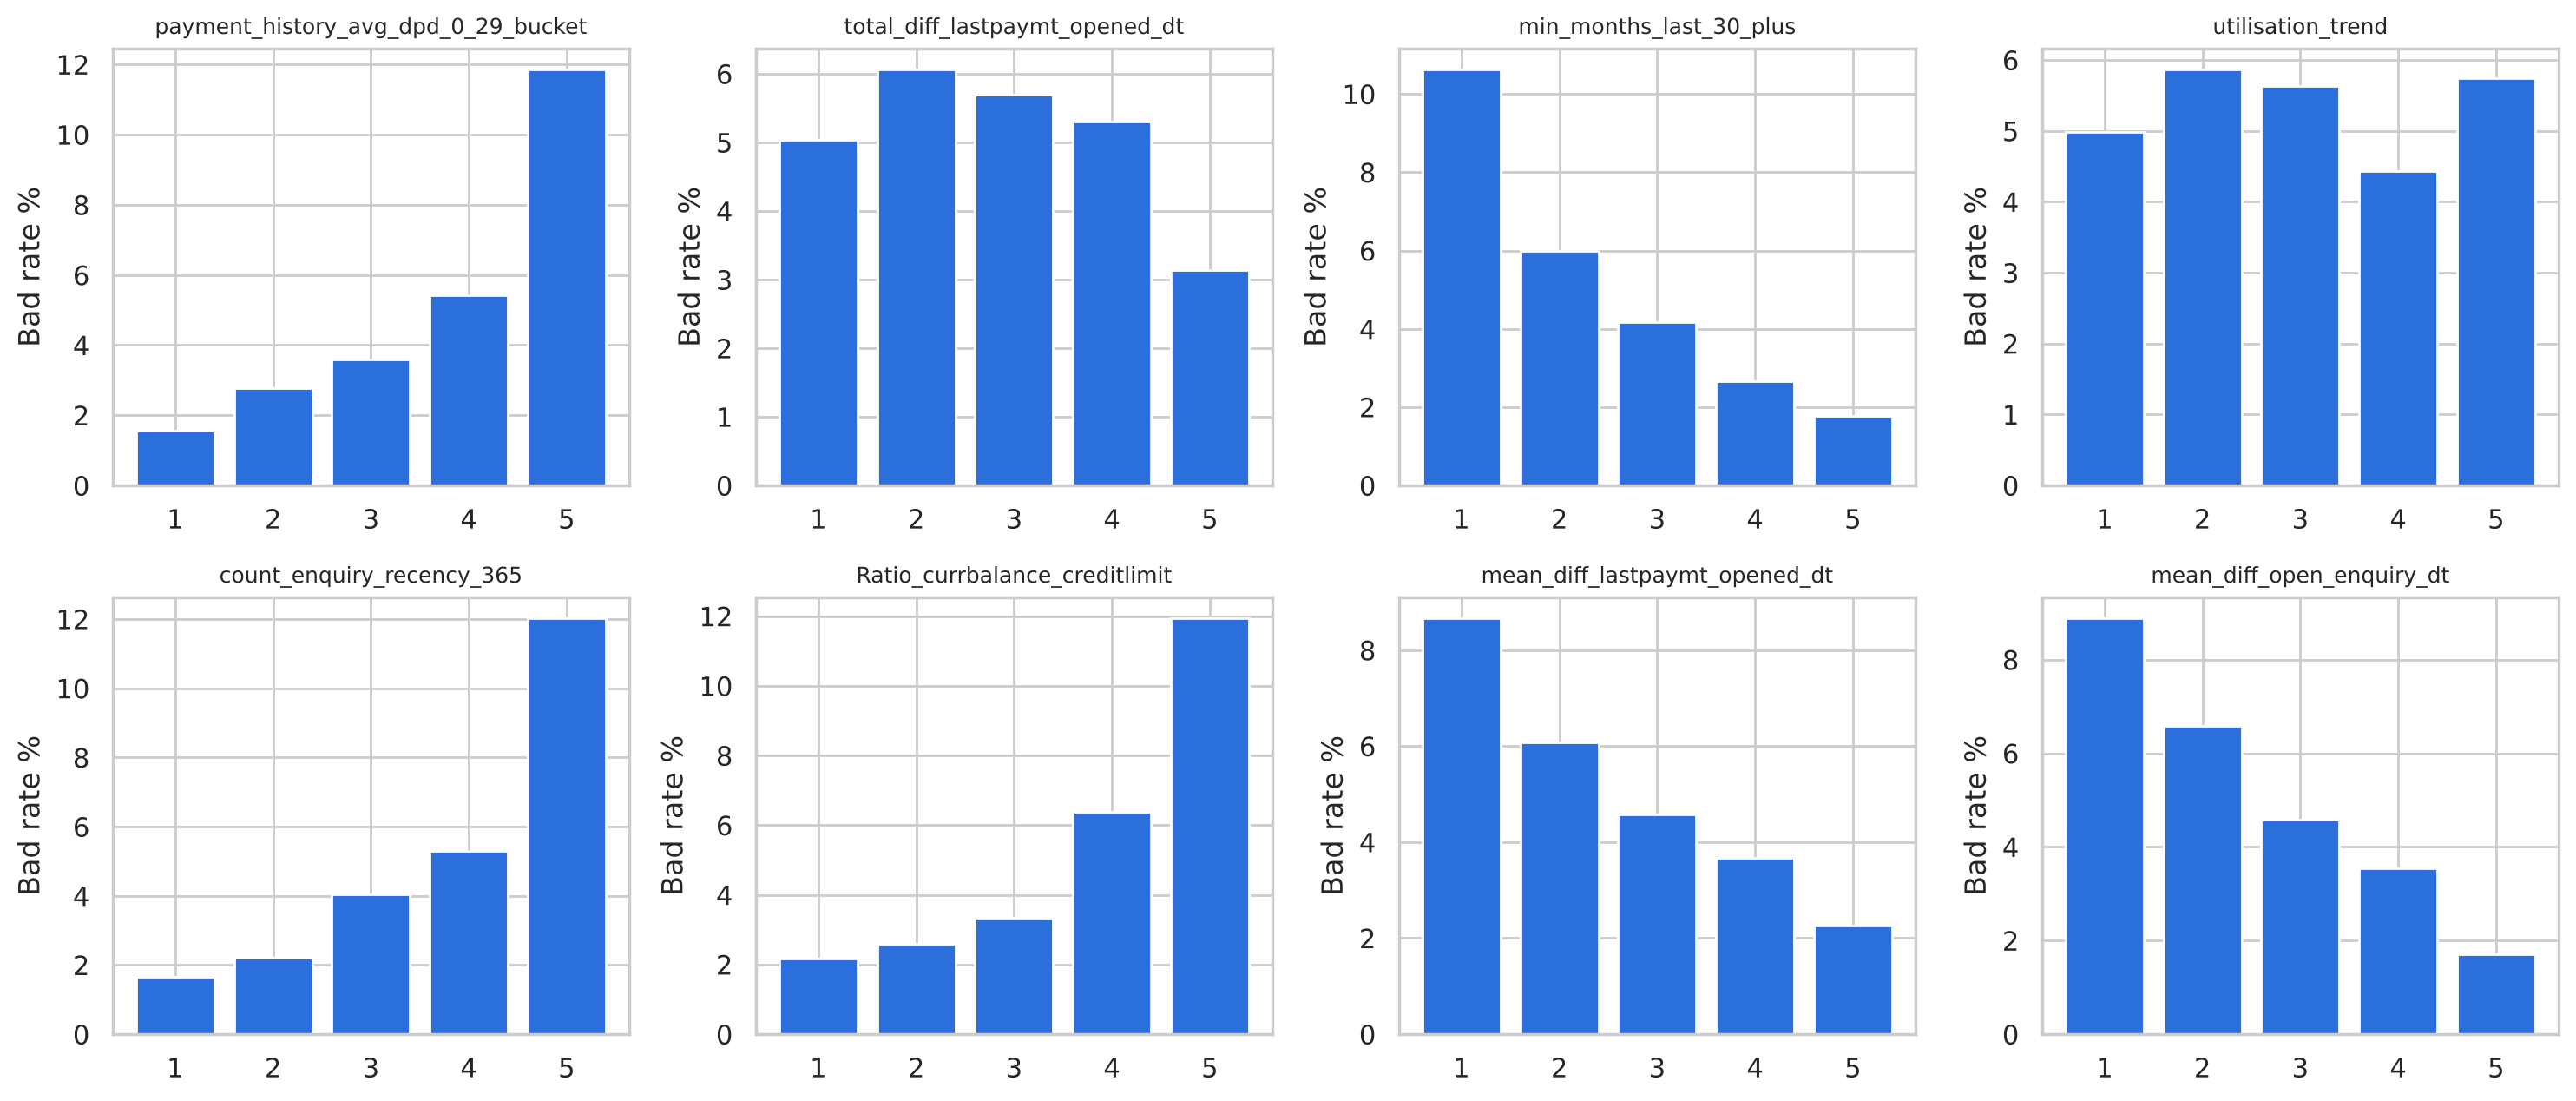

,feature,single_feature_gini,missing_share
4,count_enquiry_recency_365,42.3,0.000
0,payment_history_avg_dpd_0_29_bucket,41.9,0.000
5,Ratio_currbalance_creditlimit,39.5,0.152
2,min_months_last_30_plus,36.2,0.000
7,mean_diff_open_enquiry_dt,30.3,0.003
6,mean_diff_lastpaymt_opened_dt,26.4,0.001
1,total_diff_lastpaymt_opened_dt,7.6,0.000
3,utilisation_trend,0.7,0.165


In [7]:
suggested = ['payment_history_avg_dpd_0_29_bucket', 'total_diff_lastpaymt_opened_dt', 'min_months_last_30_plus',
             'utilisation_trend', 'count_enquiry_recency_365', 'Ratio_currbalance_creditlimit',
             'mean_diff_lastpaymt_opened_dt', 'mean_diff_open_enquiry_dt']
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
rows = []
for ax, f in zip(axes.ravel(), suggested):
    s = X[f]
    q = pd.qcut(s.rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
    br = y.groupby(q.where(s.notna())).mean() * 100
    ax.bar(br.index.astype(str), br.values, color='#2a6fdb'); ax.set_title(f, fontsize=9); ax.set_ylabel('Bad rate %')
    from sklearn.metrics import roc_auc_score
    m = s.notna()
    rows.append({'feature': f, 'single_feature_gini': round(abs(2 * roc_auc_score(y[m], s[m]) - 1) * 100, 1), 'missing_share': round(1 - m.mean(), 3)})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).sort_values('single_feature_gini', ascending=False)

**Reading the charts:** the 0-29 DPD bucket, card utilisation ratio and enquiry-recency features rise steadily from quintile 1 to 5 (more delinquency / utilisation / enquiries → more bads) and each reaches a single-feature Gini near 40 on its own. `min_months_last_30_plus` and the mean last-payment duration fall (a long time since the last 30+ DPD, or a long paying history, means lower risk).

`utilisation_trend` (as defined in the business case) is almost flat here: dividing total-based utilisation by mean-based utilisation largely cancels out, so it adds little beyond `Ratio_currbalance_creditlimit`. We keep it in the candidate list and let feature selection decide.

## 6. Correlation among engineered features

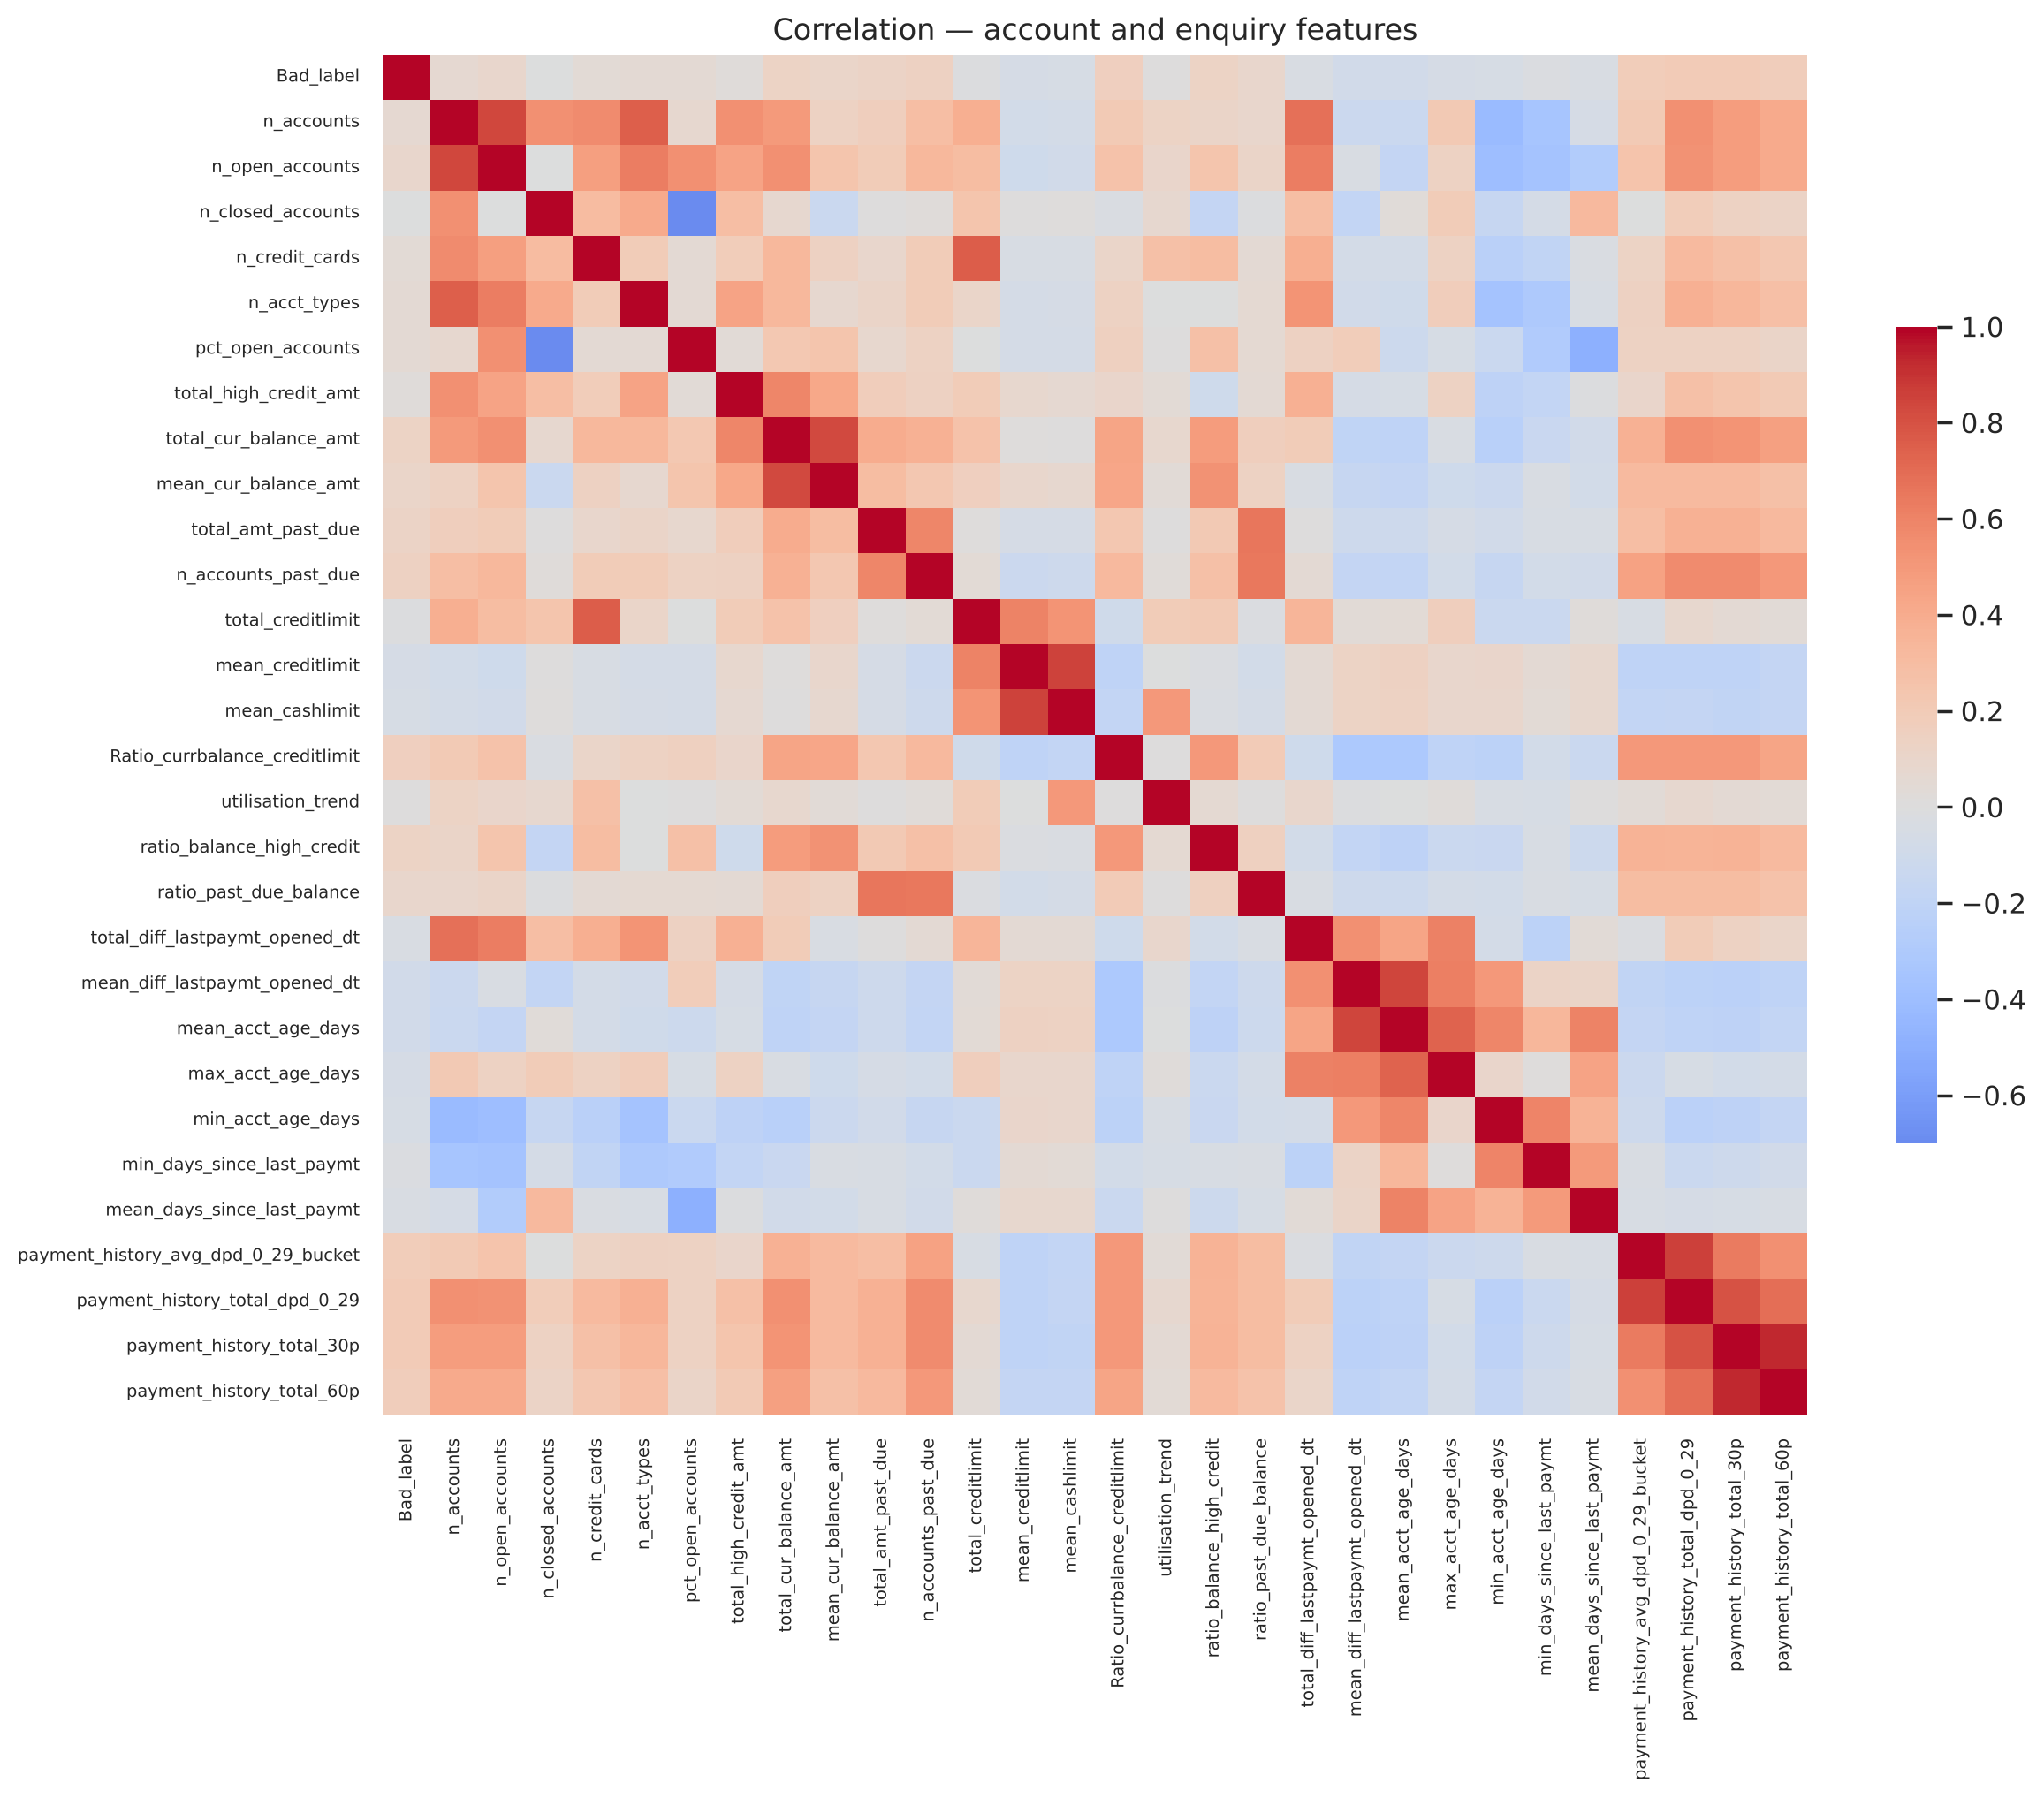

In [8]:
top = [c for c in X.columns if not c.startswith('feature_')][:30]
plt.figure(figsize=(13, 10))
sns.heatmap(X[top].corr(), cmap='coolwarm', center=0, cbar_kws={'shrink': .6}, xticklabels=True, yticklabels=True)
plt.title('Correlation — account and enquiry features'); plt.xticks(fontsize=7); plt.yticks(fontsize=7); plt.show()

Some features are naturally related (e.g. total vs mean balance). In `train.py` we drop any feature with |correlation| > 0.95 to another, then keep only features that beat random noise in a shadow-feature test.

→ Next: **Notebook 3 — Model Building & Evaluation**